In [6]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [3]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [11]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
X, Y = [], []
for w in words:
  
  #print(w)
  context = [0] * block_size
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append
  
X = torch.tensor(X)
Y = torch.tensor(Y)

In [12]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [45]:
# build the dataset
block_size = 5 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182580, 5]) torch.Size([182580])
torch.Size([22767, 5]) torch.Size([22767])
torch.Size([22799, 5]) torch.Size([22799])


In [46]:
C = torch.randn((27, 2))

In [47]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [48]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [49]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [50]:
h

tensor([[ 0.9130,  1.0000,  0.8939,  ..., -1.0000,  0.7991, -1.0000],
        [ 0.9816,  0.9864, -0.5714,  ..., -1.0000,  1.0000,  0.8707],
        [-0.9521, -0.2393,  1.0000,  ...,  1.0000,  0.7410,  1.0000],
        ...,
        [-0.9955, -0.5726,  0.9050,  ...,  1.0000, -0.9938, -0.8882],
        [ 1.0000, -0.9786, -1.0000,  ...,  1.0000,  0.0653,  0.9867],
        [-1.0000,  0.9719,  1.0000,  ...,  1.0000, -0.9947,  0.2603]])

In [51]:
h.shape

torch.Size([228146, 100])

In [52]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [53]:
logits = h @ W2 + b2

In [54]:
logits.shape

torch.Size([228146, 27])

In [55]:
counts = logits.exp()

In [56]:
prob = counts / counts.sum(1, keepdims=True)

In [57]:
prob.shape

torch.Size([228146, 27])

In [58]:
loss = -prob[torch.arange(32), Y].log().mean()
loss

IndexError: shape mismatch: indexing tensors could not be broadcast together with shapes [32], [228146]

In [59]:
# ------------ now made respectable :) ---------------

In [80]:
Xtr.shape, Ytr.shape # dataset

(torch.Size([182625, 5]), torch.Size([182625]))

In [81]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility

n_embd = 10    # dimensionality of the character embedding vectors
n_hidden = 200 # number of neurons in the hidden layer

C = torch.randn((27, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [82]:
sum(p.nelement() for p in parameters) # number of parameters in total

15897

In [83]:
for p in parameters:
  p.requires_grad = True

In [84]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [85]:
lri = []
lossi = []
stepi = []

In [86]:
for i in range(200000):
  
  # minibatch construct
  ix = torch.randint(0, Xtr.shape[0], (32,))
  
  # forward pass
  emb = C[Xtr[ix]] # (32, block_size, n_embd)
  h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1) # (32, n_hidden)
  logits = h @ W2 + b2 # (32, 27)
  loss = F.cross_entropy(logits, Ytr[ix])
  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < 100000 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

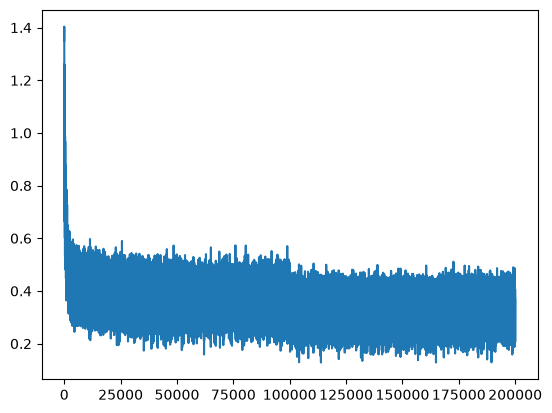

In [89]:
plt.plot(stepi, lossi)

In [90]:
emb = C[Xtr] # (N, block_size, n_embd)
h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1) # (N, n_hidden)
logits = h @ W2 + b2 # (N, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.1627, grad_fn=<NllLossBackward0>)

In [91]:
emb = C[Xdev] # (N, block_size, n_embd)
h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1 + b1) # (N, n_hidden)
logits = h @ W2 + b2 # (N, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1874, grad_fn=<NllLossBackward0>)

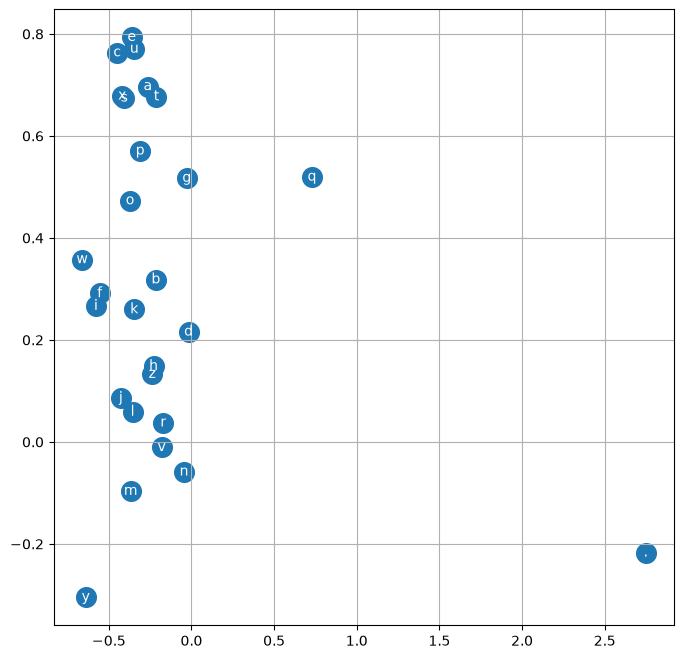

In [92]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [93]:
# training split, dev/validation split, test split
# 80%, 10%, 10%

In [40]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [42]:


# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carlah.
amorhavi.
kemili.
taty.
salani.
emmahnen.
deliah.
jareei.
nellara.
chaiivia.
leigh.
ham.
joce.
quint.
suline.
liven.
corathoniearisi.
jace.
pirra.
mel.


## Experiment: does increasing block_size (context length) reduce loss?

Train the same architecture (n_embd=10, n_hidden=200) with block_size in {2,3,4,5,6},
200,000 steps each, same lr schedule (0.1 -> 0.01 at step 100k). Compare train/dev loss.

In [ ]:
# --- block_size sweep: does more context help? ---
import time
import torch.nn.functional as F

def build_dataset_bs(words, block_size):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]
    return torch.tensor(X), torch.tensor(Y)

def train_and_eval(block_size, steps=200000, n_embd=10, n_hidden=200):
    Xtr_bs, Ytr_bs = build_dataset_bs(words[:n1], block_size)
    Xdev_bs, Ydev_bs = build_dataset_bs(words[n1:n2], block_size)

    g = torch.Generator().manual_seed(2147483647)
    C_bs  = torch.randn((27, n_embd), generator=g)
    W1_bs = torch.randn((block_size * n_embd, n_hidden), generator=g)
    b1_bs = torch.randn(n_hidden, generator=g)
    W2_bs = torch.randn((n_hidden, 27), generator=g)
    b2_bs = torch.randn(27, generator=g)
    params_bs = [C_bs, W1_bs, b1_bs, W2_bs, b2_bs]
    for p in params_bs:
        p.requires_grad = True

    torch.manual_seed(0)
    t0 = time.time()
    for i in range(steps):
        ix = torch.randint(0, Xtr_bs.shape[0], (32,))
        emb = C_bs[Xtr_bs[ix]]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_bs + b1_bs)
        logits = h @ W2_bs + b2_bs
        loss = F.cross_entropy(logits, Ytr_bs[ix])
        for p in params_bs:
            p.grad = None
        loss.backward()
        lr = 0.1 if i < 100000 else 0.01
        for p in params_bs:
            p.data += -lr * p.grad
    dt = time.time() - t0

    with torch.no_grad():
        emb = C_bs[Xtr_bs]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_bs + b1_bs)
        train_loss = F.cross_entropy(h @ W2_bs + b2_bs, Ytr_bs).item()
        emb = C_bs[Xdev_bs]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_bs + b1_bs)
        dev_loss = F.cross_entropy(h @ W2_bs + b2_bs, Ydev_bs).item()
    return train_loss, dev_loss, dt

bs_results = {}
for bs in [2, 3, 4, 5, 6]:
    tr, dv, dt = train_and_eval(bs)
    bs_results[bs] = (tr, dv)
    print(f"block_size={bs}: train_loss={tr:.4f}  dev_loss={dv:.4f}  ({dt:.1f}s)")


block_size=2: train_loss=2.2183  dev_loss=2.2450  (34.3s)
block_size=3: train_loss=2.1114  dev_loss=2.1488  (35.9s)
block_size=4: train_loss=2.1533  dev_loss=2.1910  (35.7s)
block_size=5: train_loss=2.1703  dev_loss=2.2019  (39.1s)
block_size=6: train_loss=2.2186  dev_loss=2.2318  (40.3s)


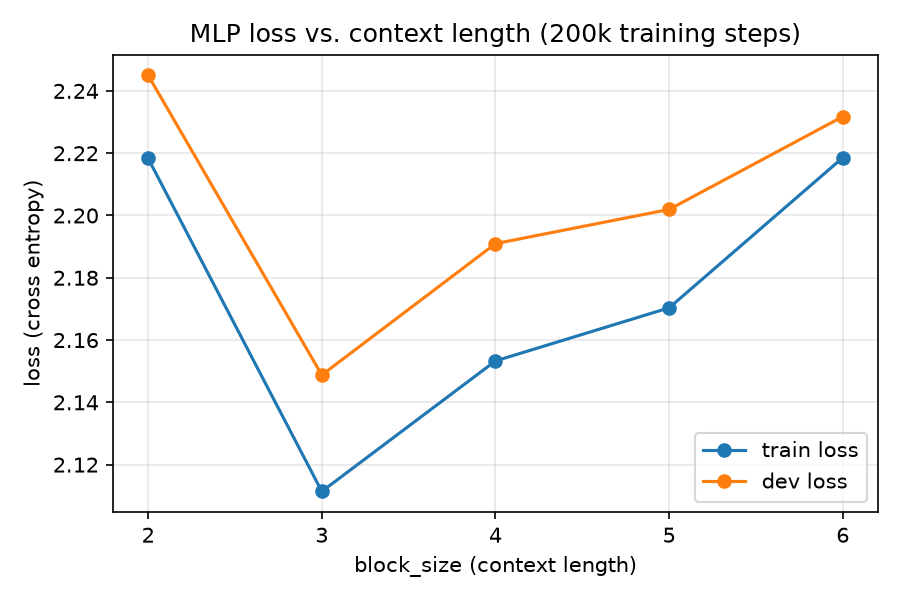

In [ ]:
# --- plot the result ---
block_sizes = sorted(bs_results.keys())
train_losses = [bs_results[bs][0] for bs in block_sizes]
dev_losses = [bs_results[bs][1] for bs in block_sizes]

plt.figure(figsize=(6,4))
plt.plot(block_sizes, train_losses, marker='o', label='train loss')
plt.plot(block_sizes, dev_losses, marker='o', label='dev loss')
plt.xlabel('block_size (context length)')
plt.ylabel('loss (cross entropy)')
plt.title('MLP loss vs. context length (200k training steps)')
plt.xticks(block_sizes)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Experiment: does increasing n_embd (embedding size) reduce loss?

block_size fixed at 3 (the winner from the previous sweep), n_hidden fixed at 200, 200,000 steps each, same lr schedule. Sweep n_embd in {2, 5, 10, 25, 50}.

In [ ]:
# --- n_embd sweep: does a bigger embedding help? (block_size fixed at 3) ---
def train_and_eval_embd(n_embd, block_size=3, n_hidden=200, steps=200000):
    g = torch.Generator().manual_seed(2147483647)
    C_e  = torch.randn((27, n_embd), generator=g)
    W1_e = torch.randn((block_size * n_embd, n_hidden), generator=g)
    b1_e = torch.randn(n_hidden, generator=g)
    W2_e = torch.randn((n_hidden, 27), generator=g)
    b2_e = torch.randn(27, generator=g)
    params_e = [C_e, W1_e, b1_e, W2_e, b2_e]
    for p in params_e:
        p.requires_grad = True

    torch.manual_seed(0)
    t0 = time.time()
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (32,))
        emb = C_e[Xtr[ix]]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_e + b1_e)
        logits = h @ W2_e + b2_e
        loss = F.cross_entropy(logits, Ytr[ix])
        for p in params_e:
            p.grad = None
        loss.backward()
        lr = 0.1 if i < 100000 else 0.01
        for p in params_e:
            p.data += -lr * p.grad
    dt = time.time() - t0

    with torch.no_grad():
        emb = C_e[Xtr]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_e + b1_e)
        train_loss = F.cross_entropy(h @ W2_e + b2_e, Ytr).item()
        emb = C_e[Xdev]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_e + b1_e)
        dev_loss = F.cross_entropy(h @ W2_e + b2_e, Ydev).item()
    return train_loss, dev_loss, dt

embd_results = {}
for ne in [2, 5, 10, 25, 50]:
    tr, dv, dt = train_and_eval_embd(ne)
    embd_results[ne] = (tr, dv)
    print(f"n_embd={ne}: train_loss={tr:.4f}  dev_loss={dv:.4f}  ({dt:.1f}s)")


n_embd=2: train_loss=2.2286  dev_loss=2.2387  (37.8s)
n_embd=5: train_loss=2.1755  dev_loss=2.1993  (33.9s)
n_embd=10: train_loss=2.1114  dev_loss=2.1488  (33.9s)
n_embd=25: train_loss=2.0665  dev_loss=2.1496  (42.9s)
n_embd=50: train_loss=2.0511  dev_loss=2.1378  (87.1s)


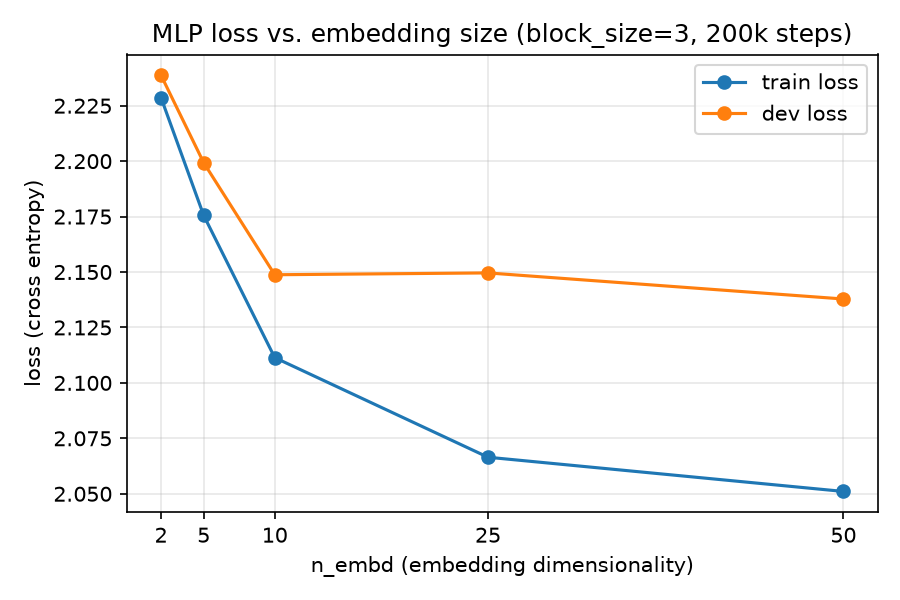

In [ ]:
# --- plot the result ---
ns = sorted(embd_results.keys())
train_losses = [embd_results[n][0] for n in ns]
dev_losses = [embd_results[n][1] for n in ns]

plt.figure(figsize=(6,4))
plt.plot(ns, train_losses, marker='o', label='train loss')
plt.plot(ns, dev_losses, marker='o', label='dev loss')
plt.xlabel('n_embd (embedding dimensionality)')
plt.ylabel('loss (cross entropy)')
plt.title('MLP loss vs. embedding size (block_size=3, 200k steps)')
plt.xticks(ns)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Experiment: does increasing n_hidden (hidden layer width) reduce loss?

block_size fixed at 3, n_embd fixed at 10 (lecture default), 200,000 steps each, same lr schedule. Sweep n_hidden in {50, 100, 200, 400, 800}.

In [ ]:
# --- n_hidden sweep: does a wider hidden layer help? (block_size=3, n_embd=10 fixed) ---
def train_and_eval_hidden(n_hidden, block_size=3, n_embd=10, steps=200000):
    g = torch.Generator().manual_seed(2147483647)
    C_h  = torch.randn((27, n_embd), generator=g)
    W1_h = torch.randn((block_size * n_embd, n_hidden), generator=g)
    b1_h = torch.randn(n_hidden, generator=g)
    W2_h = torch.randn((n_hidden, 27), generator=g)
    b2_h = torch.randn(27, generator=g)
    params_h = [C_h, W1_h, b1_h, W2_h, b2_h]
    for p in params_h:
        p.requires_grad = True

    torch.manual_seed(0)
    t0 = time.time()
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (32,))
        emb = C_h[Xtr[ix]]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_h + b1_h)
        logits = h @ W2_h + b2_h
        loss = F.cross_entropy(logits, Ytr[ix])
        for p in params_h:
            p.grad = None
        loss.backward()
        lr = 0.1 if i < 100000 else 0.01
        for p in params_h:
            p.data += -lr * p.grad
    dt = time.time() - t0

    with torch.no_grad():
        emb = C_h[Xtr]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_h + b1_h)
        train_loss = F.cross_entropy(h @ W2_h + b2_h, Ytr).item()
        emb = C_h[Xdev]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_h + b1_h)
        dev_loss = F.cross_entropy(h @ W2_h + b2_h, Ydev).item()
    return train_loss, dev_loss, dt

hidden_results = {}
for nh in [50, 100, 200, 400, 800]:
    tr, dv, dt = train_and_eval_hidden(nh)
    hidden_results[nh] = (tr, dv)
    print(f"n_hidden={nh}: train_loss={tr:.4f}  dev_loss={dv:.4f}  ({dt:.1f}s)")


n_hidden=50: train_loss=2.1955  dev_loss=2.2086  (26.9s)
n_hidden=100: train_loss=2.1441  dev_loss=2.1681  (30.4s)
n_hidden=200: train_loss=2.1114  dev_loss=2.1488  (34.9s)
n_hidden=400: train_loss=2.1072  dev_loss=2.1887  (45.4s)
n_hidden=800: train_loss=2.1590  dev_loss=2.2303  (65.5s)


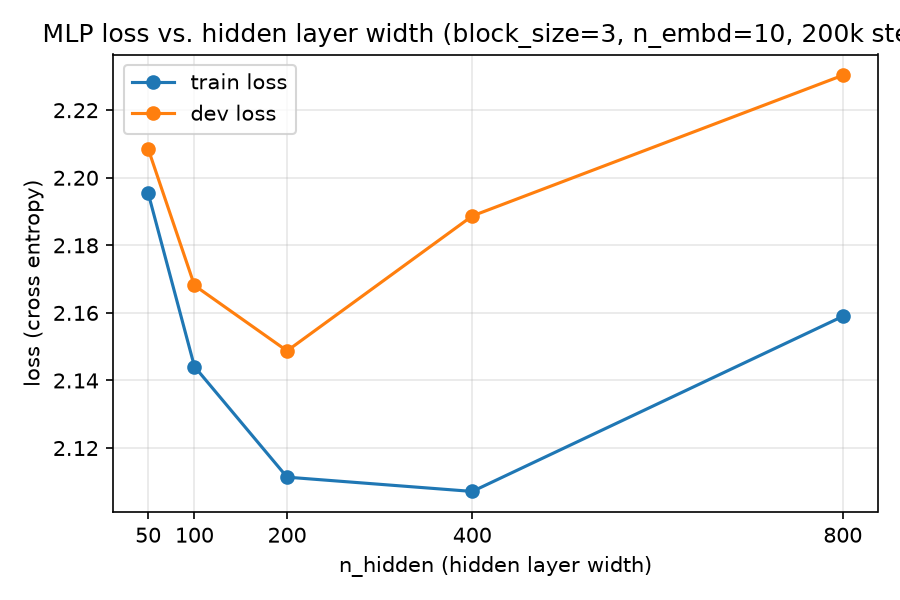

In [ ]:
# --- plot the result ---
ns = sorted(hidden_results.keys())
train_losses = [hidden_results[n][0] for n in ns]
dev_losses = [hidden_results[n][1] for n in ns]

plt.figure(figsize=(6,4))
plt.plot(ns, train_losses, marker='o', label='train loss')
plt.plot(ns, dev_losses, marker='o', label='dev loss')
plt.xlabel('n_hidden (hidden layer width)')
plt.ylabel('loss (cross entropy)')
plt.title('MLP loss vs. hidden layer width (block_size=3, n_embd=10, 200k steps)')
plt.xticks(ns)
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Investigating the n_hidden=800 anomaly: tanh saturation and dead neurons

The n_hidden sweep showed something odd: going from 400->800 made BOTH train and dev loss
worse, not just dev loss (which would be ordinary overfitting). That points to an
*optimization* problem, not a generalization problem. Hypothesis: raw unscaled `torch.randn`
init means pre-activations (the values fed into `tanh`) get pushed further from zero as the
network gets wider, driving more neurons into tanh's saturated region (|preact| large ->
gradient ~0 -> neuron stops learning). Let's measure it directly: pre-activation distributions
and saturation fraction, at init and after 200k training steps, for n_hidden=200 vs 800.

In [ ]:
# --- measure tanh saturation: compare n_hidden=200 vs 800, at init and after training ---
def make_params_sat(n_hidden):
    g = torch.Generator().manual_seed(2147483647)
    C_s  = torch.randn((27, n_embd), generator=g)
    W1_s = torch.randn((block_size * n_embd, n_hidden), generator=g)
    b1_s = torch.randn(n_hidden, generator=g)
    W2_s = torch.randn((n_hidden, 27), generator=g)
    b2_s = torch.randn(27, generator=g)
    return [C_s, W1_s, b1_s, W2_s, b2_s]

def preact_stats(params, batch_size=1000, seed=999):
    C_s, W1_s, b1_s, W2_s, b2_s = params
    nh = W1_s.shape[1]
    gg = torch.Generator().manual_seed(seed)
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=gg)
    with torch.no_grad():
        emb = C_s[Xtr[ix]]
        preact = emb.view(-1, block_size * n_embd) @ W1_s + b1_s
        h = torch.tanh(preact)
    saturated_frac = (h.abs() > 0.99).float().mean().item()
    dead_neurons = (h.abs() > 0.99).all(0).sum().item()
    return preact.std().item(), preact.abs().max().item(), saturated_frac, dead_neurons

def train_params(params, steps=200000):
    for p in params:
        p.requires_grad = True
    torch.manual_seed(0)
    for i in range(steps):
        ix = torch.randint(0, Xtr.shape[0], (32,))
        C_s, W1_s, b1_s, W2_s, b2_s = params
        emb = C_s[Xtr[ix]]
        h = torch.tanh(emb.view(-1, block_size * n_embd) @ W1_s + b1_s)
        logits = h @ W2_s + b2_s
        loss = F.cross_entropy(logits, Ytr[ix])
        for p in params:
            p.grad = None
        loss.backward()
        lr = 0.1 if i < 100000 else 0.01
        for p in params:
            p.data += -lr * p.grad
    return params

for nh in [200, 800]:
    init_params = make_params_sat(nh)
    std0, max0, sat0, dead0 = preact_stats(init_params)

    trained_params = train_params(make_params_sat(nh), steps=200000)
    std1, max1, sat1, dead1 = preact_stats([p.detach() for p in trained_params])

    print(f"n_hidden={nh}")
    print(f"  AT INIT    : preact std={std0:.2f}  max|preact|={max0:.2f}  saturated={sat0*100:.1f}%  dead_neurons={dead0}/{nh}")
    print(f"  AFTER TRAIN: preact std={std1:.2f}  max|preact|={max1:.2f}  saturated={sat1*100:.1f}%  dead_neurons={dead1}/{nh}")


n_hidden=200
  AT INIT    : preact std=5.46  max|preact|=25.52  saturated=62.2%  dead_neurons=0/200
  AFTER TRAIN: preact std=3.35  max|preact|=14.14  saturated=44.2%  dead_neurons=0/200
n_hidden=800
  AT INIT    : preact std=5.38  max|preact|=31.07  saturated=61.2%  dead_neurons=0/800
  AFTER TRAIN: preact std=18.49  max|preact|=78.75  saturated=97.2%  dead_neurons=18/800


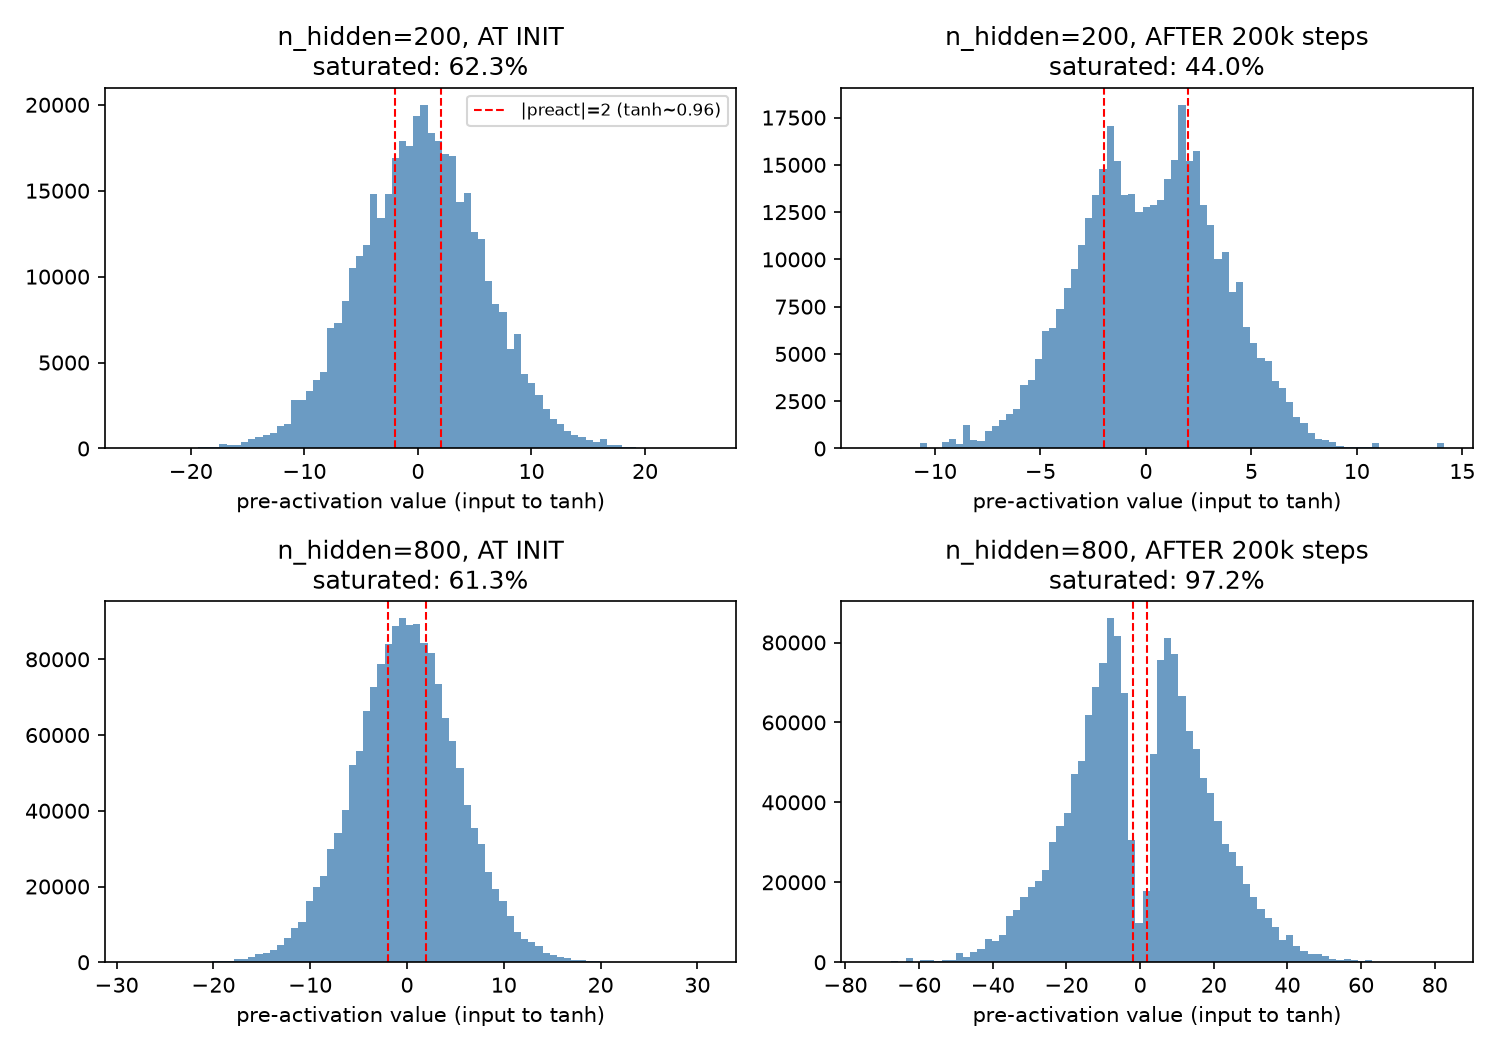

In [ ]:
# --- visualize the pre-activation distributions ---
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
configs = [(200, False, "n_hidden=200, AT INIT"),
           (200, True,  "n_hidden=200, AFTER 200k steps"),
           (800, False, "n_hidden=800, AT INIT"),
           (800, True,  "n_hidden=800, AFTER 200k steps")]

for ax, (nh, trained, title) in zip(axes.flat, configs):
    p = make_params_sat(nh)
    if trained:
        p = train_params(p, steps=200000)
        p = [x.detach() for x in p]
    C_s, W1_s, b1_s, W2_s, b2_s = p
    g2 = torch.Generator().manual_seed(999)
    ix = torch.randint(0, Xtr.shape[0], (2000,), generator=g2)
    with torch.no_grad():
        emb = C_s[Xtr[ix]]
        preact = (emb.view(-1, block_size * n_embd) @ W1_s + b1_s).flatten().numpy()
    ax.hist(preact, bins=80, color='steelblue', alpha=0.8)
    ax.axvline(2, color='red', linestyle='--', linewidth=1)
    ax.axvline(-2, color='red', linestyle='--', linewidth=1)
    sat = (np.abs(np.tanh(preact)) > 0.99).mean() * 100
    ax.set_title(f"{title}\nsaturated: {sat:.1f}%")
    ax.set_xlabel('pre-activation (input to tanh)')

plt.tight_layout()
plt.show()


**Takeaway:** both widths start similarly saturated (~61-62%) because fan-in (block_size*n_embd=30)
is the same either way. But during training, width 200 self-corrects (saturation drops to 44.2%,
pre-activation std shrinks 5.46->3.35), while width 800 blows up (saturation rises to 97.2%,
std grows 5.38->18.49, and 18/800 neurons go permanently dead -- saturated for every example
in the batch, contributing zero gradient). Root cause: W2 sums over 4x more hidden units at
width 800, so with the same fixed learning rate, gradients and weight updates are proportionally
larger relative to what's well-calibrated for width 200 -- training overshoots instead of
converging. This is precisely the motivation for the next lecture's proper weight
initialization (scaling by 1/sqrt(fan_in)) and batch normalization.